# 04 — Cost-based threshold, thin-file analysis, explainability and fairness

Uses the LightGBM model, its out-of-fold (OOF) training predictions and the holdout predictions saved by
notebook 03. **Thresholds are always chosen on the training OOF predictions**; the holdout is used only to
report the effect of a decision that was already made.

Shared code: `src/cost.py` (cost model, threshold sweep), `src/explain.py` (SHAP, reason codes),
`src/modeling.py` (fitting / CV for the ablation and fairness models).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import json
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="All-NaN slice encountered")

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from matplotlib.ticker import FuncFormatter, PercentFormatter
from sklearn.metrics import roc_auc_score

from src.config import ID, MODELS_DIR, PROCESSED_DIR, RANDOM_STATE, TARGET
from src.cost import (BASE_LGD, BASE_MARGIN, approve_all_cost, decision_summary, optimal_threshold,
                      sensitivity_grid, threshold_sweep)
from src.explain import mean_abs_shap, numeric_view, reason_codes, shap_explanation
from src.modeling import cross_validate_gbm, fit_lgbm, load_or_create_split, train_holdout
from src.plotting import INK_2, MUTED, SEQ_BLUE, SERIES, savefig, set_style

set_style()
pd.set_option("display.max_columns", 30, "display.width", 180, "display.max_colwidth", 80)
millions = FuncFormatter(lambda v, _: f"{v / 1e6:,.0f}M")

In [2]:
model_table = pd.read_parquet(PROCESSED_DIR / "model_table.parquet")
split, created = load_or_create_split(model_table)
assert not created, "split must come from notebook 03"
train, holdout = train_holdout(model_table, split)

cfg = json.loads((MODELS_DIR / "lgbm_best_params.json").read_text())
FEATURES, BEST_PARAMS = cfg["features"], cfg["params"]
lgbm = joblib.load(MODELS_DIR / "lgbm_model.joblib")

oof = pd.read_parquet(PROCESSED_DIR / "oof_lgbm.parquet")
preds = pd.read_parquet(PROCESSED_DIR / "holdout_predictions.parquet")
assert (oof[ID].to_numpy() == train[ID].to_numpy()).all() and (preds[ID].to_numpy() == holdout[ID].to_numpy()).all()
assert np.allclose(lgbm.predict_proba(holdout[FEATURES])[:, 1], preds["p_lgbm"])

y_oof, p_oof, credit_oof = train[TARGET].to_numpy(), oof["oof_lgbm"].to_numpy(), train["AMT_CREDIT"].to_numpy()
y_ho, p_ho, credit_ho = holdout[TARGET].to_numpy(), preds["p_lgbm"].to_numpy(), holdout["AMT_CREDIT"].to_numpy()
print(f"train OOF rows: {len(y_oof):,} | holdout rows: {len(y_ho):,}")
print(f"best LightGBM params: {BEST_PARAMS}")

train OOF rows: 246,005 | holdout rows: 61,502
best LightGBM params: {'subsample': 0.8, 'reg_lambda': 10, 'num_leaves': 15, 'min_child_samples': 100, 'learning_rate': 0.02, 'colsample_bytree': 0.3}


## A. Cost-based decision threshold

**Assumptions (not provided with the data):**
- approving an applicant who defaults (false negative) costs **LGD × AMT_CREDIT**, base LGD = 0.60;
- rejecting an applicant who would have repaid (false positive) costs **MARGIN × AMT_CREDIT** in lost profit,
  base MARGIN = 0.15;
- correct decisions cost 0. Amounts are in the data's undisclosed currency.

An applicant is rejected when the predicted default probability is ≥ threshold. Thresholds 0.01–0.99 are swept
on the **training OOF predictions** to choose the cost-minimising threshold, which is then applied to the holdout.

In [3]:
sweep_oof = threshold_sweep(y_oof, p_oof, credit_oof)
T_STAR = optimal_threshold(sweep_oof)
print(f"cost-minimising threshold on train OOF: {T_STAR:.2f}")
print(f"break-even threshold if probabilities were calibrated: MARGIN / (LGD + MARGIN) = "
      f"{BASE_MARGIN / (BASE_LGD + BASE_MARGIN):.2f}")
print(f"mean OOF predicted probability: {p_oof.mean():.4f} vs actual train default rate: {y_oof.mean():.4f}")

sweep_ho = threshold_sweep(y_ho, p_ho, credit_ho)
print(f"(reference only, not used for any decision) threshold that would minimise holdout cost: "
      f"{optimal_threshold(sweep_ho):.2f}")

cost-minimising threshold on train OOF: 0.70
break-even threshold if probabilities were calibrated: MARGIN / (LGD + MARGIN) = 0.20
mean OOF predicted probability: 0.3853 vs actual train default rate: 0.0807


(reference only, not used for any decision) threshold that would minimise holdout cost: 0.70


In [4]:
scenarios = {"Approve everyone": 1.01, "Threshold 0.50": 0.50, f"Cost-optimal threshold {T_STAR:.2f}": T_STAR}
base_cost = approve_all_cost(y_ho, credit_ho)
rows = []
for name, t in scenarios.items():
    s = decision_summary(y_ho, p_ho, credit_ho, t)
    rows.append({"policy": name, "approval_rate": s["approval_rate"], "default_rate_approved": s["default_rate_approved"],
                 "defaulters_approved": s["n_fn"], "good_rejected": s["n_fp"], "loss_from_defaults": s["fn_cost"],
                 "lost_margin": s["fp_cost"], "total_cost": s["total_cost"],
                 "saving_vs_approve_all": base_cost - s["total_cost"],
                 "saving_pct": 1 - s["total_cost"] / base_cost})
policy_table = pd.DataFrame(rows).set_index("policy")
display(policy_table.style.format({"approval_rate": "{:.2%}", "default_rate_approved": "{:.2%}",
                                   "defaulters_approved": "{:,.0f}", "good_rejected": "{:,.0f}",
                                   "loss_from_defaults": "{:,.0f}", "lost_margin": "{:,.0f}", "total_cost": "{:,.0f}",
                                   "saving_vs_approve_all": "{:,.0f}", "saving_pct": "{:.2%}"}))
c05 = policy_table.loc["Threshold 0.50", "total_cost"]
copt = policy_table.iloc[2]["total_cost"]
print(f"holdout cost at the optimal threshold vs 0.50: {copt - c05:,.0f} ({copt / c05 - 1:+.2%})")

,approval_rate,default_rate_approved,defaulters_approved,good_rejected,loss_from_defaults,lost_margin,total_cost,saving_vs_approve_all,saving_pct
policy,,,,,,,,,
Approve everyone,100.00%,8.07%,"4,965",0,"1,665,214,629",0,"1,665,214,629",0,0.00%
Threshold 0.50,71.34%,3.70%,"1,622","14,285","593,285,604","1,162,878,545","1,756,164,150","-90,949,520",-5.46%
Cost-optimal threshold 0.70,89.44%,5.60%,"3,080","4,608","1,083,329,527","348,029,027","1,431,358,554","233,856,075",14.04%


holdout cost at the optimal threshold vs 0.50: -324,805,596 (-18.50%)


saved reports/figures/21_cost_vs_threshold.png


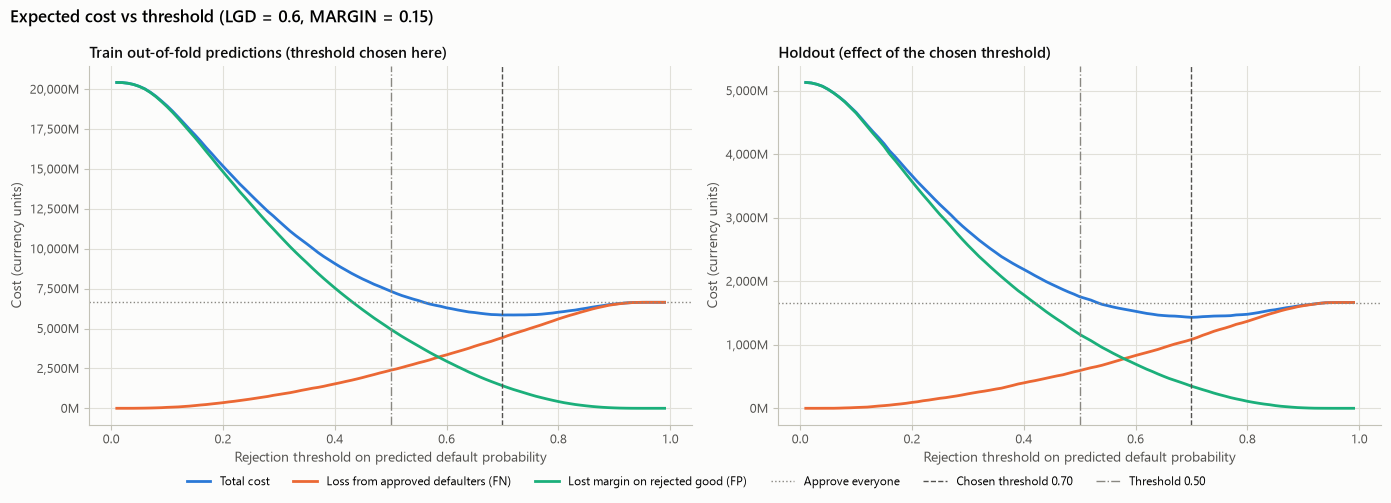

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, sweep, title in [(axes[0], sweep_oof, "Train out-of-fold predictions (threshold chosen here)"),
                         (axes[1], sweep_ho, "Holdout (effect of the chosen threshold)")]:
    ax.plot(sweep["threshold"], sweep["total_cost"], color=SERIES[0], label="Total cost")
    ax.plot(sweep["threshold"], sweep["fn_cost"], color=SERIES[1], label="Loss from approved defaulters (FN)")
    ax.plot(sweep["threshold"], sweep["fp_cost"], color=SERIES[2], label="Lost margin on rejected good (FP)")
    y_all = approve_all_cost(y_oof if sweep is sweep_oof else y_ho, credit_oof if sweep is sweep_oof else credit_ho)
    ax.axhline(y_all, color=MUTED, linestyle=":", linewidth=1, label="Approve everyone")
    ax.axvline(T_STAR, color=INK_2, linestyle="--", linewidth=1, label=f"Chosen threshold {T_STAR:.2f}")
    ax.axvline(0.5, color=MUTED, linestyle="-.", linewidth=1, label="Threshold 0.50")
    ax.yaxis.set_major_formatter(millions)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Rejection threshold on predicted default probability")
    ax.set_ylabel("Cost (currency units)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=8.5, bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"Expected cost vs threshold (LGD = {BASE_LGD}, MARGIN = {BASE_MARGIN})", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
savefig(fig, "21_cost_vs_threshold.png")
plt.show()

**Insight:** With LGD = 0.60 and MARGIN = 0.15, the cost-minimising threshold chosen on the training OOF predictions is
**0.70**. The threshold that would have minimised holdout cost (computed for reference only) is also 0.70, so the
choice transfers well to unseen applicants. On the holdout:
- approving everyone costs 1,665,214,629;
- the default 0.5 threshold is *worse* than approving everyone (1,756,164,150, i.e. −5.46%) because it rejects
  14,285 good applicants;
- the cost-optimal threshold costs 1,431,358,554, a saving of 233,856,075 (**14.04%**) vs approving everyone and
  18.50% less than at 0.5.

The optimum is far above the break-even of 0.20 that calibrated probabilities would imply, because the
class-weighted model's scores are inflated (mean OOF prediction 0.3853 vs an actual default rate of 0.0807).

saved reports/figures/22_approval_vs_default_rate.png


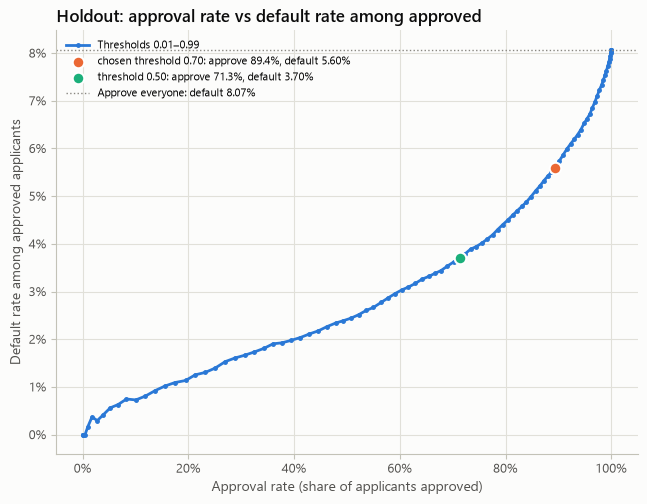

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(sweep_ho["approval_rate"], sweep_ho["default_rate_approved"], color=SERIES[0], marker="o", markersize=2.5,
        label="Thresholds 0.01–0.99")
for t, name, color in [(T_STAR, f"chosen threshold {T_STAR:.2f}", SERIES[1]), (0.5, "threshold 0.50", SERIES[2])]:
    r = sweep_ho.loc[np.isclose(sweep_ho["threshold"], t)].iloc[0]
    ax.scatter(r["approval_rate"], r["default_rate_approved"], s=70, color=color, zorder=3,
               edgecolor="white", linewidth=1.5, label=f"{name}: approve {r['approval_rate']:.1%}, "
                                                    f"default {r['default_rate_approved']:.2%}")
ax.axhline(y_ho.mean(), color=MUTED, linestyle=":", linewidth=1, label=f"Approve everyone: default {y_ho.mean():.2%}")
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_title("Holdout: approval rate vs default rate among approved", loc="left")
ax.set_xlabel("Approval rate (share of applicants approved)")
ax.set_ylabel("Default rate among approved applicants")
ax.legend(loc="upper left", fontsize=8)
savefig(fig, "22_approval_vs_default_rate.png")
plt.show()

**Insight:** At the chosen threshold 89.44% of holdout applicants are approved and the default rate among them falls
from 8.07% to 5.60% (3,080 defaulters are still approved; 4,608 good applicants are rejected). Threshold 0.5 would
approve only 71.34% of applicants (default rate 3.70% among them). The curve is the lender's trade-off: a lower
default rate among approved customers is only reachable by turning away more applicants.

### Sensitivity analysis (assumed cost parameters)
LGD and MARGIN are **assumptions**. For each combination the threshold is again chosen on the training OOF
predictions and then reported on the holdout.

LGD,MARGIN,optimal_threshold,approval_rate,default_rate_approved,cost_at_threshold,cost_approve_all,saving_vs_approve_all
0.400000,0.100000,0.70,89.44%,5.60%,"954,239,036","1,110,143,086",14.04%
0.400000,0.150000,0.79,95.37%,6.61%,"1,025,911,835","1,110,143,086",7.59%
0.400000,0.200000,0.83,97.35%,7.10%,"1,059,831,221","1,110,143,086",4.53%
0.600000,0.100000,0.64,84.82%,4.99%,"1,287,286,886","1,665,214,629",22.70%
0.600000,0.150000,0.70,89.44%,5.60%,"1,431,358,554","1,665,214,629",14.04%
0.600000,0.200000,0.77,94.26%,6.40%,"1,514,245,301","1,665,214,629",9.07%
0.800000,0.100000,0.57,78.52%,4.30%,"1,553,412,385","2,220,286,172",30.04%
0.800000,0.150000,0.68,87.96%,5.42%,"1,789,834,722","2,220,286,172",19.39%
0.800000,0.200000,0.70,89.44%,5.60%,"1,908,478,072","2,220,286,172",14.04%


saved reports/figures/23_threshold_sensitivity.png


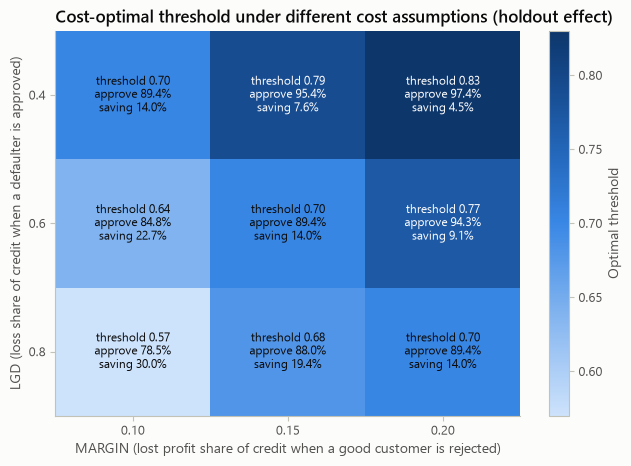

In [7]:
LGDS, MARGINS = (0.4, 0.6, 0.8), (0.10, 0.15, 0.20)
grid = sensitivity_grid(y_oof, p_oof, credit_oof, y_ho, p_ho, credit_ho, LGDS, MARGINS)
display(grid.style.format({"optimal_threshold": "{:.2f}", "approval_rate": "{:.2%}", "default_rate_approved": "{:.2%}",
                           "cost_at_threshold": "{:,.0f}", "cost_approve_all": "{:,.0f}",
                           "saving_vs_approve_all": "{:.2%}"}).hide(axis="index"))

heat = grid.pivot(index="LGD", columns="MARGIN", values="optimal_threshold")
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(heat.to_numpy(), cmap=SEQ_BLUE, aspect="auto")
for i, lgd in enumerate(heat.index):
    for j, margin in enumerate(heat.columns):
        r = grid[(grid["LGD"] == lgd) & (grid["MARGIN"] == margin)].iloc[0]
        dark = r["optimal_threshold"] > heat.to_numpy().mean()
        ax.text(j, i, f"threshold {r['optimal_threshold']:.2f}\napprove {r['approval_rate']:.1%}\n"
                      f"saving {r['saving_vs_approve_all']:.1%}", ha="center", va="center", fontsize=8.5,
                color="white" if dark else "#0b0b0b")
ax.set_xticks(range(len(heat.columns)), [f"{m:.2f}" for m in heat.columns])
ax.set_yticks(range(len(heat.index)), [f"{l:.1f}" for l in heat.index])
ax.set_xlabel("MARGIN (lost profit share of credit when a good customer is rejected)")
ax.set_ylabel("LGD (loss share of credit when a defaulter is approved)")
ax.set_title("Cost-optimal threshold under different cost assumptions (holdout effect)", loc="left")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Optimal threshold")
savefig(fig, "23_threshold_sensitivity.png")
plt.show()

**Insight (these cost parameters are assumptions):** Across the 3 × 3 grid the optimal threshold ranges from 0.57
(LGD 0.8, MARGIN 0.10) to 0.83 (LGD 0.4, MARGIN 0.20), with approval rates from 78.52% to 97.35% and holdout savings
vs approving everyone from 4.53% to 30.04%. A higher loss given default pushes the threshold down (reject more); a
higher margin pushes it up (approve more). Only the ratio of the two costs matters: the three combinations with
MARGIN / LGD = 0.25 (0.4/0.10, 0.6/0.15, 0.8/0.20) all give threshold 0.70. In every scenario the cost-based policy
is cheaper than approving everyone.

## B. Thin-file analysis (core research question)

### B1. Holdout AUC by credit-history group
95% intervals are percentile bootstrap intervals (200 resamples of the group, `random_state=42`).

In [8]:
rng = np.random.default_rng(RANDOM_STATE)


def auc_with_ci(y, p, n_boot=200):
    y, p = np.asarray(y), np.asarray(p)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            boots.append(roc_auc_score(y[idx], p[idx]))
    return roc_auc_score(y, p), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


groups = {
    "All holdout": np.ones(len(holdout), dtype=bool),
    "Bureau history: yes": holdout["HAS_BUREAU_HISTORY"].to_numpy() == 1,
    "Bureau history: no": holdout["HAS_BUREAU_HISTORY"].to_numpy() == 0,
    "Previous application: yes": holdout["HAS_PREV_APPLICATION"].to_numpy() == 1,
    "Previous application: no": holdout["HAS_PREV_APPLICATION"].to_numpy() == 0,
}
model_probs = {"LightGBM": p_ho, "Logistic regression": preds["p_logreg"].to_numpy(), "XGBoost": preds["p_xgb"].to_numpy()}
rows = []
for gname, mask in groups.items():
    row = {"group": gname, "applicants": int(mask.sum()), "default_rate": y_ho[mask].mean()}
    for mname, prob in model_probs.items():
        auc, lo, hi = auc_with_ci(y_ho[mask], prob[mask])
        row.update({f"{mname} AUC": auc, f"{mname} CI low": lo, f"{mname} CI high": hi})
    rows.append(row)
group_auc = pd.DataFrame(rows).set_index("group")
display(group_auc.style.format({"applicants": "{:,}", "default_rate": "{:.2%}"} |
                               {c: "{:.4f}" for c in group_auc.columns if "AUC" in c or "CI" in c}))

,applicants,default_rate,LightGBM AUC,LightGBM CI low,LightGBM CI high,Logistic regression AUC,Logistic regression CI low,Logistic regression CI high,XGBoost AUC,XGBoost CI low,XGBoost CI high
group,,,,,,,,,,,
All holdout,"61,502",8.07%,0.7819,0.7756,0.7880,0.7641,0.7583,0.7713,0.7744,0.7682,0.7806
Bureau history: yes,"52,747",7.73%,0.7837,0.7764,0.7914,0.7678,0.7591,0.7758,0.7761,0.7693,0.7816
Bureau history: no,"8,755",10.17%,0.7645,0.7512,0.7794,0.7348,0.7176,0.7531,0.7586,0.7387,0.7721
Previous application: yes,"58,211",8.20%,0.7811,0.7755,0.7871,0.7633,0.7564,0.7700,0.7736,0.7669,0.7798
Previous application: no,"3,291",5.74%,0.7882,0.7602,0.8227,0.7655,0.7330,0.7961,0.7802,0.7522,0.8057


saved reports/figures/24_auc_by_history_group.png


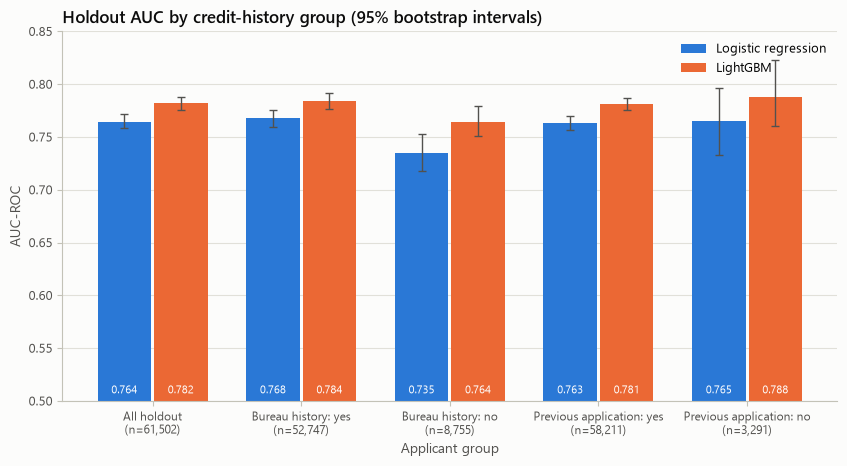

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
names = list(groups)
x = np.arange(len(names))
for k, (mname, color) in enumerate([("Logistic regression", SERIES[0]), ("LightGBM", SERIES[1])]):
    auc = group_auc[f"{mname} AUC"].to_numpy()
    err = np.vstack([auc - group_auc[f"{mname} CI low"], group_auc[f"{mname} CI high"] - auc])
    ax.bar(x + (k - 0.5) * 0.38, auc, width=0.36, color=color, label=mname, yerr=err, capsize=3,
           error_kw={"ecolor": INK_2, "elinewidth": 1})
    for xi, a in zip(x + (k - 0.5) * 0.38, auc):
        ax.text(xi, 0.505, f"{a:.3f}", ha="center", va="bottom", fontsize=8, color="white")
ax.set_xticks(x, [f"{n}\n(n={group_auc.loc[n, 'applicants']:,})" for n in names], fontsize=8.5)
ax.set_ylim(0.5, 0.85)
ax.set_title("Holdout AUC by credit-history group (95% bootstrap intervals)", loc="left")
ax.set_xlabel("Applicant group")
ax.set_ylabel("AUC-ROC")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
savefig(fig, "24_auc_by_history_group.png")
plt.show()

**Insight:** The model still ranks risk well for thin-file applicants, though less well than for others. LightGBM's
holdout AUC is 0.7645 (95% interval 0.7512–0.7794) for the 8,755 applicants without bureau history versus 0.7837
(0.7764–0.7914) for those with it. The logistic regression loses more on the thin-file group (0.7348 vs 0.7678). For
the 3,291 applicants without a previous Home Credit application LightGBM's AUC is 0.7882, but the interval is wide
(0.7602–0.8227) because the group is small and has only 5.74% defaults.

### B2. Ablation: how much do external scores and bureau data contribute?

`EXT_SOURCE_*` are external credit scores (a proxy for credit history). Each variant is a LightGBM with the
**same tuned hyperparameters**, refitted on the training set with the same early-stopping scheme:
- **No EXT_SOURCE**: drops `EXT_SOURCE_1/2/3`, `EXT_SOURCE_MEAN`, `EXT_SOURCE_STD`;
- **No bureau**: drops all `BUR_` features and `HAS_BUREAU_HISTORY`;
- **Alternative data only**: drops both groups; what remains is the application form (demographics, employment,
  loan terms, documents, housing) plus Home Credit's own previous-application and instalment history.

In [10]:
EXT_COLS = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EXT_SOURCE_MEAN", "EXT_SOURCE_STD"]
BUR_COLS = [c for c in FEATURES if c.startswith("BUR_")] + ["HAS_BUREAU_HISTORY"]
variants = {
    "Full model": [],
    "No EXT_SOURCE": EXT_COLS,
    "No bureau": BUR_COLS,
    "Alternative data only": EXT_COLS + BUR_COLS,
}
no_bureau = groups["Bureau history: no"]
has_bureau = groups["Bureau history: yes"]
ablation_models, ablation_probs, rows = {}, {}, []
for name, drop in variants.items():
    feats = [f for f in FEATURES if f not in drop]
    model = lgbm if not drop else fit_lgbm(BEST_PARAMS, train[feats], train[TARGET])
    prob = model.predict_proba(holdout[feats])[:, 1]
    ablation_models[name], ablation_probs[name] = (model, feats), prob
    auc_all, lo_all, hi_all = auc_with_ci(y_ho, prob)
    auc_nb, lo_nb, hi_nb = auc_with_ci(y_ho[no_bureau], prob[no_bureau])
    rows.append({"variant": name, "n_features": len(feats), "best_iteration": model.best_iteration_,
                 "AUC all": auc_all, "all CI low": lo_all, "all CI high": hi_all,
                 "AUC no-bureau": auc_nb, "no-bureau CI low": lo_nb, "no-bureau CI high": hi_nb,
                 "AUC with-bureau": roc_auc_score(y_ho[has_bureau], prob[has_bureau])})
ablation = pd.DataFrame(rows).set_index("variant")
ablation["drop vs full (all)"] = ablation["AUC all"] - ablation.loc["Full model", "AUC all"]
ablation["drop vs full (no-bureau)"] = ablation["AUC no-bureau"] - ablation.loc["Full model", "AUC no-bureau"]
display(ablation.round(4))

,n_features,best_iteration,AUC all,all CI low,all CI high,AUC no-bureau,no-bureau CI low,no-bureau CI high,AUC with-bureau,drop vs full (all),drop vs full (no-bureau)
variant,,,,,,,,,,,
Full model,161,2203,0.7819,0.7757,0.7883,0.7645,0.7529,0.7815,0.7837,0.0000,0.0000
No EXT_SOURCE,156,2213,0.7548,0.7472,0.7625,0.7499,0.7339,0.7643,0.7543,-0.0271,-0.0146
No bureau,150,1661,0.7783,0.7724,0.7850,0.7654,0.7462,0.7789,0.7793,-0.0036,0.0009
Alternative data only,145,1312,0.7373,0.7314,0.7448,0.7507,0.7341,0.7677,0.7331,-0.0446,-0.0138


saved reports/figures/25_ablation_auc.png


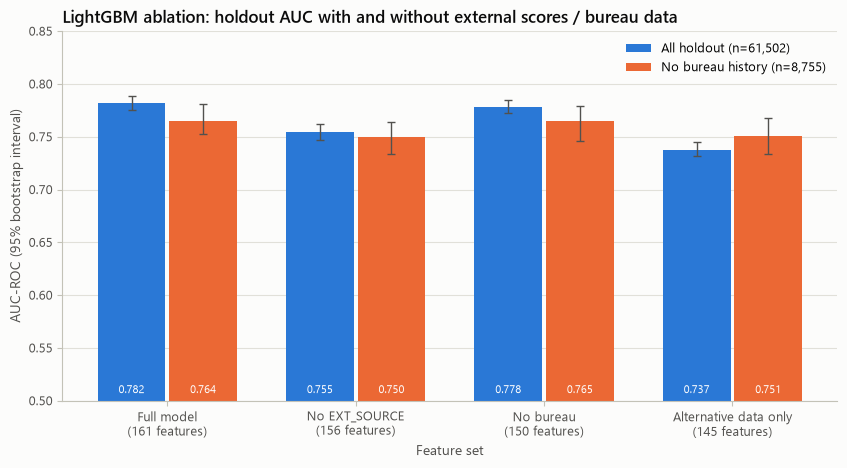

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(ablation))
for k, (col, lo, hi, label, color) in enumerate([
        ("AUC all", "all CI low", "all CI high", f"All holdout (n={len(y_ho):,})", SERIES[0]),
        ("AUC no-bureau", "no-bureau CI low", "no-bureau CI high",
         f"No bureau history (n={int(no_bureau.sum()):,})", SERIES[1])]):
    auc = ablation[col].to_numpy()
    err = np.vstack([auc - ablation[lo], ablation[hi] - auc])
    ax.bar(x + (k - 0.5) * 0.38, auc, width=0.36, color=color, label=label, yerr=err, capsize=3,
           error_kw={"ecolor": INK_2, "elinewidth": 1})
    for xi, a in zip(x + (k - 0.5) * 0.38, auc):
        ax.text(xi, 0.505, f"{a:.3f}", ha="center", va="bottom", fontsize=8, color="white")
ax.set_xticks(x, [f"{v}\n({ablation.loc[v, 'n_features']} features)" for v in ablation.index], fontsize=9)
ax.set_ylim(0.5, 0.85)
ax.set_title("LightGBM ablation: holdout AUC with and without external scores / bureau data", loc="left")
ax.set_xlabel("Feature set")
ax.set_ylabel("AUC-ROC (95% bootstrap interval)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
savefig(fig, "25_ablation_auc.png")
plt.show()

**Insight:**
- Removing the external scores costs the most: overall AUC falls from 0.7819 to 0.7548 (−0.0271).
- Removing the bureau features barely matters overall (0.7783, −0.0036) and not at all for the no-bureau group
  (0.7654 vs 0.7645), as expected, since these applicants have no bureau data.
- With **alternative data only** (no external scores, no bureau; 145 features) the model still reaches AUC 0.7373
  overall and **0.7507 (95% interval 0.7341–0.7677) on the no-bureau group**, only 0.0138 below the full model on
  that group. The alternative-data model actually ranks thin-file applicants better than applicants with a bureau file
  (0.7331), so application and behavioural data carry relatively more signal exactly where credit history is missing.

## C. Explainability with SHAP
TreeSHAP values from `shap.TreeExplainer` on the final LightGBM, for a random sample of 5,000 holdout applicants.
Values are in **log-odds of default** of the class-weighted model; positive = pushes towards rejection.

In [12]:
shap_rows = holdout.sample(5000, random_state=RANDOM_STATE)
X_shap = shap_rows[FEATURES]
ex = shap_explanation(lgbm, X_shap)
raw = lgbm.predict(X_shap, raw_score=True)
print(f"SHAP additivity check, max |sum(SHAP) + base - raw score|: "
      f"{np.abs(ex.values.sum(axis=1) + np.ravel(ex.base_values) - raw).max():.2e}")
ex_plot = shap.Explanation(values=ex.values, base_values=ex.base_values, data=numeric_view(X_shap).to_numpy(),
                           display_data=X_shap.astype(object).to_numpy(), feature_names=FEATURES)
global_importance = mean_abs_shap(ex)
display(global_importance.head(20).to_frame("mean |SHAP|").round(4))

SHAP additivity check, max |sum(SHAP) + base - raw score|: 1.51e-14


,mean |SHAP|
EXT_SOURCE_MEAN,0.3610
CREDIT_TERM,0.1265
PREV_APP_CREDIT_RATIO_MEAN,0.1208
GOODS_CREDIT_RATIO,0.1160
ORGANIZATION_TYPE,0.1124
CODE_GENDER,0.1095
EXT_SOURCE_3,0.1046
INST_LATE_SHARE,0.1007
EXT_SOURCE_2,0.0945
EXT_SOURCE_1,0.0905


In [13]:
# Direction check for the top 8 drivers: mean SHAP by decile of the feature's value (D1 = lowest value, deciles
# over non-missing rows, ties split by row order) and the rank correlation between value and SHAP.
shap_df = pd.DataFrame(ex.values, columns=FEATURES, index=X_shap.index)
top8 = global_importance.head(8).index
top_num = [f for f in top8 if not isinstance(X_shap[f].dtype, pd.CategoricalDtype)]
direction = pd.DataFrame({
    f: shap_df[f].groupby(pd.qcut(X_shap[f].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)]),
                          observed=True).mean()
    for f in top_num}).T
direction.insert(0, "spearman(value, SHAP)", [X_shap[f].corr(shap_df[f], method="spearman") for f in top_num])
print("mean SHAP (log-odds) by value decile, numeric top-8 drivers:")
display(direction.round(3))
print("CODE_GENDER mean SHAP by value:",
      shap_df["CODE_GENDER"].groupby(X_shap["CODE_GENDER"].astype(str)).mean().round(3).to_dict())
print("CREDIT_TERM range in the highest decile:",
      f"{X_shap['CREDIT_TERM'][X_shap['CREDIT_TERM'].rank(method='first') > 0.9 * X_shap['CREDIT_TERM'].notna().sum()].min():.4f}",
      f"to {X_shap['CREDIT_TERM'].max():.4f}")

mean SHAP (log-odds) by value decile, numeric top-8 drivers:


,"spearman(value, SHAP)",D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
EXT_SOURCE_MEAN,-0.993,0.820,0.511,0.297,0.128,0.023,-0.104,-0.278,-0.331,-0.459,-0.643
CREDIT_TERM,0.073,-0.072,-0.011,-0.001,-0.064,0.193,0.088,0.133,-0.027,0.139,-0.333
PREV_APP_CREDIT_RATIO_MEAN,-0.947,0.168,0.168,0.162,0.118,0.017,-0.063,-0.067,-0.099,-0.164,-0.204
GOODS_CREDIT_RATIO,-0.912,0.268,0.116,0.109,0.083,-0.025,-0.074,-0.119,-0.119,-0.118,-0.119
EXT_SOURCE_3,-0.891,0.373,0.169,0.056,0.008,-0.063,-0.099,-0.101,-0.104,-0.118,-0.114
INST_LATE_SHARE,0.925,-0.093,-0.092,-0.092,-0.092,-0.090,-0.035,0.026,0.091,0.158,0.245


CODE_GENDER mean SHAP by value: {'F': -0.084, 'M': 0.159}
CREDIT_TERM range in the highest decile: 0.0935 to 0.1212


saved reports/figures/26_shap_beeswarm.png


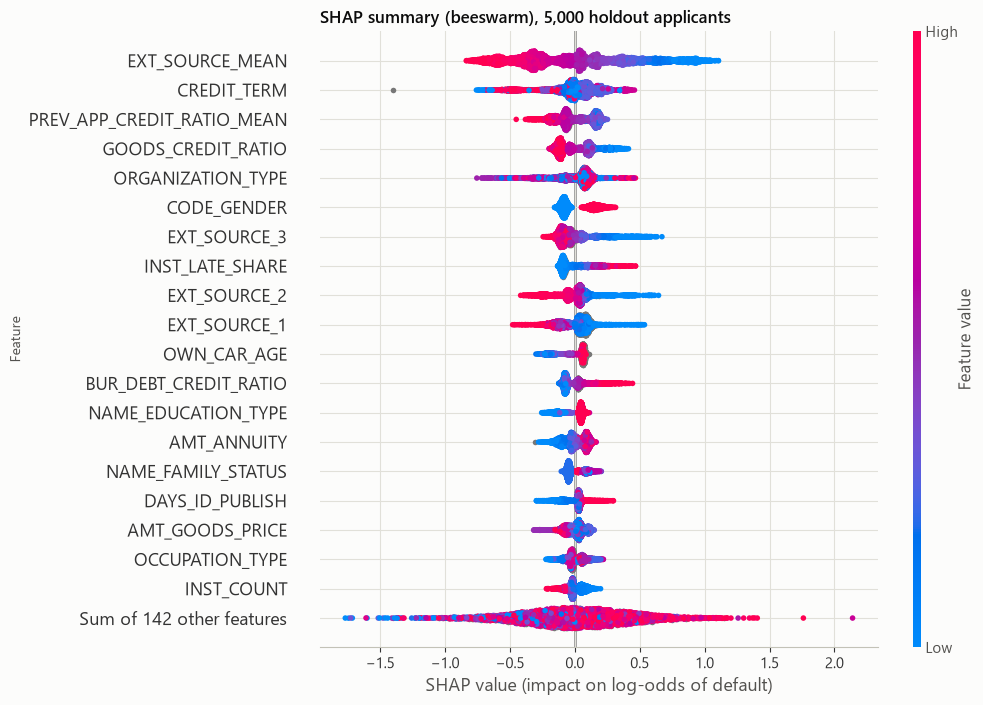

In [14]:
shap.plots.beeswarm(ex_plot, max_display=20, show=False, plot_size=(9, 8))
fig = plt.gcf()
plt.title("SHAP summary (beeswarm), 5,000 holdout applicants", loc="left", fontsize=12, fontweight="semibold")
plt.xlabel("SHAP value (impact on log-odds of default)")
plt.ylabel("Feature")
savefig(fig, "26_shap_beeswarm.png")
plt.show()

**Insight:** Low `EXT_SOURCE_MEAN` (blue points) pushes predictions strongly towards default; it is by far the most
important feature, with a mean |SHAP| 2.85 times that of the next one (mean SHAP +0.820 in its lowest decile vs
−0.643 in its highest, table above). Loan structure comes next. A goods price that covers less of the loan (low
`GOODS_CREDIT_RATIO`, +0.268 in D1) and a low requested-to-granted ratio on previous applications
(`PREV_APP_CREDIT_RATIO_MEAN`, +0.168 in D1) raise risk. `CREDIT_TERM` (annuity / credit) is **not monotonic** (rank
correlation between value and SHAP only 0.073): mid-range values raise risk (D5 +0.193, D7 +0.133, D9 +0.139), while
the shortest loans in the highest decile (annuity 9.35–12.12% of the credit) lower it the most (−0.333). Behavioural
alternative data also matters: a high share of late instalments (`INST_LATE_SHARE`) raises risk (+0.245 in D10).
`CODE_GENDER` is in the top 6 (mean SHAP +0.159 for men vs −0.084 for women), a fairness concern examined in
section D.

saved reports/figures/27_shap_bar.png


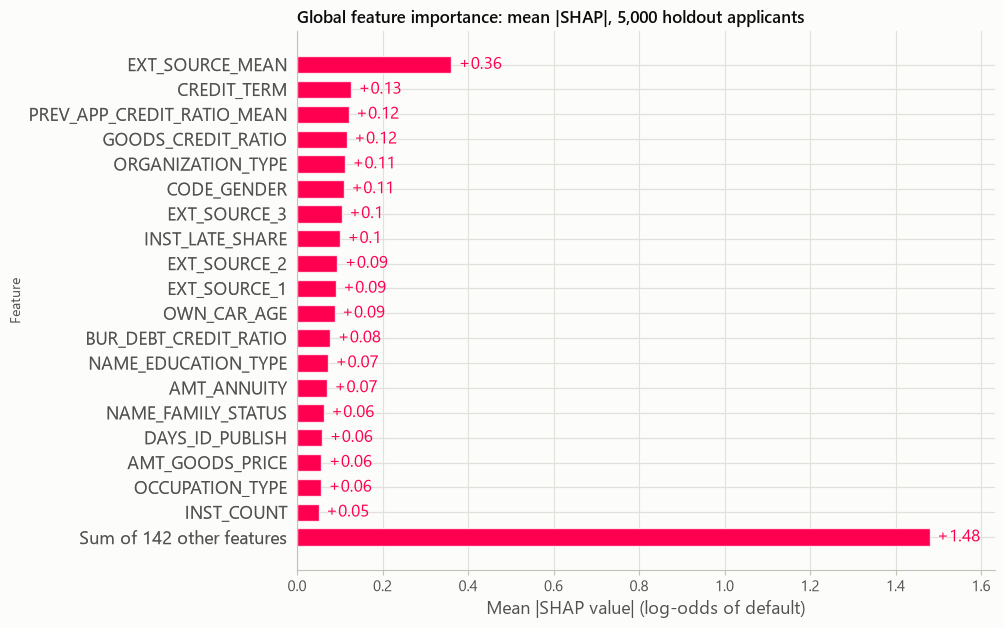

In [15]:
shap.plots.bar(ex_plot, max_display=20, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 7)
plt.title("Global feature importance: mean |SHAP|, 5,000 holdout applicants", loc="left", fontsize=12,
          fontweight="semibold")
plt.xlabel("Mean |SHAP value| (log-odds of default)")
plt.ylabel("Feature")
savefig(fig, "27_shap_bar.png")
plt.show()

**Insight:** By mean |SHAP| the top 5 drivers are `EXT_SOURCE_MEAN` (0.3610), `CREDIT_TERM` (0.1265),
`PREV_APP_CREDIT_RATIO_MEAN` (0.1208), `GOODS_CREDIT_RATIO` (0.1160) and `ORGANIZATION_TYPE` (0.1124), followed by
`CODE_GENDER` (0.1095). The order differs from the gain ranking in notebook 03 (where `ORGANIZATION_TYPE` was second):
gain measures how much a feature is used for splits, SHAP how much it moves individual predictions.

### C2. Local explanations: three applicants rejected at the chosen threshold
Chosen from the SHAP sample among applicants with predicted probability ≥ the cost-optimal threshold: the
highest-risk applicant, the median rejected applicant, and the rejected applicant closest to the threshold.

rejected in SHAP sample at threshold 0.70: 542 of 5,000


saved reports/figures/28_shap_waterfall_applicant_1.png


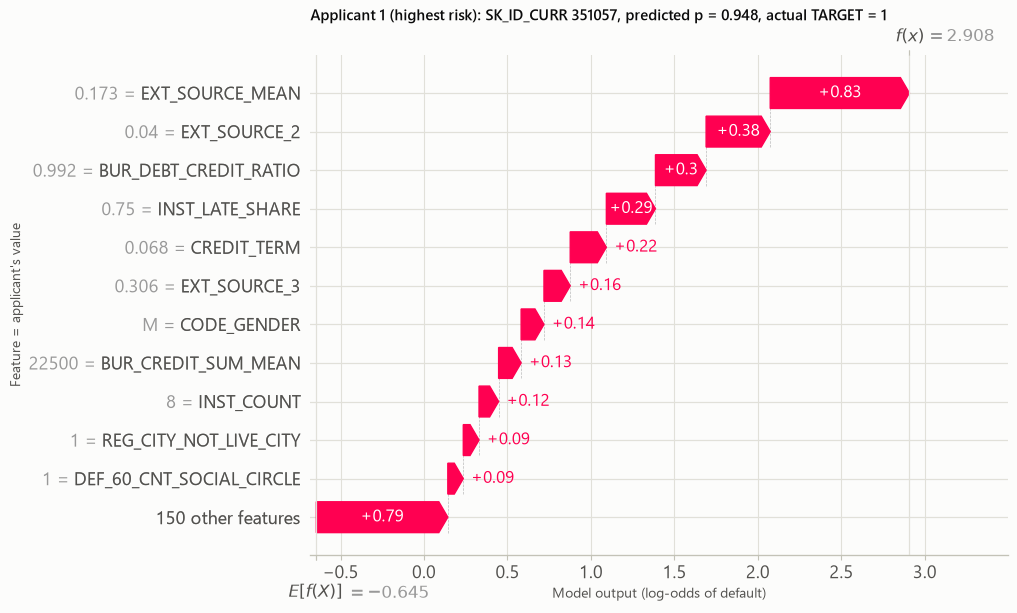

saved reports/figures/29_shap_waterfall_applicant_2.png


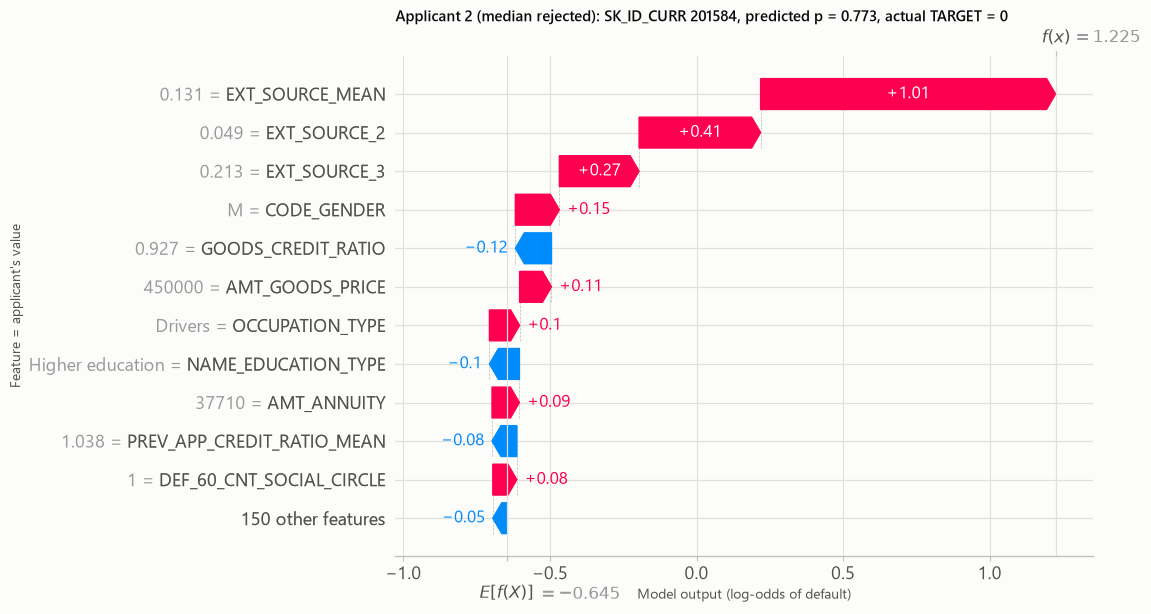

saved reports/figures/30_shap_waterfall_applicant_3.png


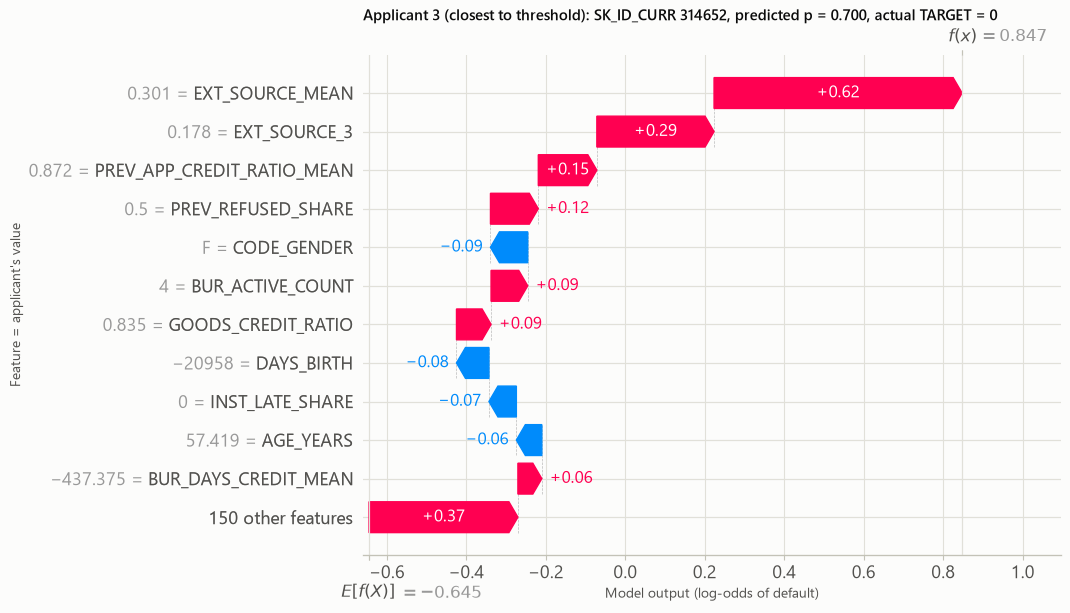

applicant,feature,shap_log_odds,reason
"1 (highest risk, SK_ID_CURR 351057, p=0.948, TARGET=1)",EXT_SOURCE_MEAN,+0.834,Average external credit score is 0.17 (scale 0-1)
"1 (highest risk, SK_ID_CURR 351057, p=0.948, TARGET=1)",EXT_SOURCE_2,+0.384,External credit score 2 is 0.04 (scale 0-1)
"1 (highest risk, SK_ID_CURR 351057, p=0.948, TARGET=1)",BUR_DEBT_CREDIT_RATIO,+0.303,Outstanding bureau debt is 99% of bureau credit
"2 (median rejected, SK_ID_CURR 201584, p=0.773, TARGET=0)",EXT_SOURCE_MEAN,+1.006,Average external credit score is 0.13 (scale 0-1)
"2 (median rejected, SK_ID_CURR 201584, p=0.773, TARGET=0)",EXT_SOURCE_2,+0.415,External credit score 2 is 0.05 (scale 0-1)
"2 (median rejected, SK_ID_CURR 201584, p=0.773, TARGET=0)",EXT_SOURCE_3,+0.272,External credit score 3 is 0.21 (scale 0-1)
"3 (closest to threshold, SK_ID_CURR 314652, p=0.700, TARGET=0)",EXT_SOURCE_MEAN,+0.624,Average external credit score is 0.30 (scale 0-1)
"3 (closest to threshold, SK_ID_CURR 314652, p=0.700, TARGET=0)",EXT_SOURCE_3,+0.295,External credit score 3 is 0.18 (scale 0-1)
"3 (closest to threshold, SK_ID_CURR 314652, p=0.700, TARGET=0)",PREV_APP_CREDIT_RATIO_MEAN,+0.147,"Previously requested 87% of the credit granted, on average"


In [16]:
p_shap = lgbm.predict_proba(X_shap)[:, 1]
rejected = np.where(p_shap >= T_STAR)[0]
order = rejected[np.argsort(p_shap[rejected])]
picks = {"highest risk": order[-1], "median rejected": order[len(order) // 2], "closest to threshold": order[0]}
print(f"rejected in SHAP sample at threshold {T_STAR:.2f}: {len(rejected):,} of {len(X_shap):,}")

reason_tables = []
for k, (label, i) in enumerate(picks.items(), start=1):
    sk_id = int(shap_rows[ID].iloc[i])
    actual = int(shap_rows[TARGET].iloc[i])
    shap.plots.waterfall(ex_plot[i], max_display=12, show=False)
    fig = plt.gcf()
    fig.set_size_inches(9, 6.5)
    plt.title(f"Applicant {k} ({label}): SK_ID_CURR {sk_id}, predicted p = {p_shap[i]:.3f}, actual TARGET = {actual}",
              loc="left", fontsize=11, fontweight="semibold")
    fig.axes[0].set_xlabel("Model output (log-odds of default)")
    fig.axes[0].set_ylabel("Feature = applicant's value")
    savefig(fig, f"{27 + k}_shap_waterfall_applicant_{k}.png")
    plt.show()
    codes = reason_codes(ex.values[i], X_shap.iloc[i], top_n=3)
    codes.insert(0, "applicant", f"{k} ({label}, SK_ID_CURR {sk_id}, p={p_shap[i]:.3f}, TARGET={actual})")
    reason_tables.append(codes)

reasons = pd.concat(reason_tables, ignore_index=True)
display(reasons.style.format({"shap_log_odds": "{:+.3f}"}).hide(axis="index"))

**Insight:** All three rejected applicants are driven mainly by low external credit scores (averages 0.17, 0.13 and
0.30). Applicant 1 (p = 0.948, who did default) also has outstanding bureau debt at 99% of their bureau credit; the
waterfall shows `CODE_GENDER = M` adding +0.14 to their log-odds. Applicant 3, just above the threshold (p = 0.700),
is pushed over by low `EXT_SOURCE_3` (0.18) and by a previous requested-to-granted credit ratio of 87%. Applicants 2
and 3 actually repaid (TARGET = 0): they are examples of the good customers the cost-optimal policy accepts losing.

### C3. SHAP for applicants with no Credit Bureau history
All holdout applicants with `HAS_BUREAU_HISTORY = 0`, explained with the full model. The table also shows the most
important features for the same applicants under the *alternative-data-only* ablation model.

saved reports/figures/31_shap_beeswarm_no_bureau.png


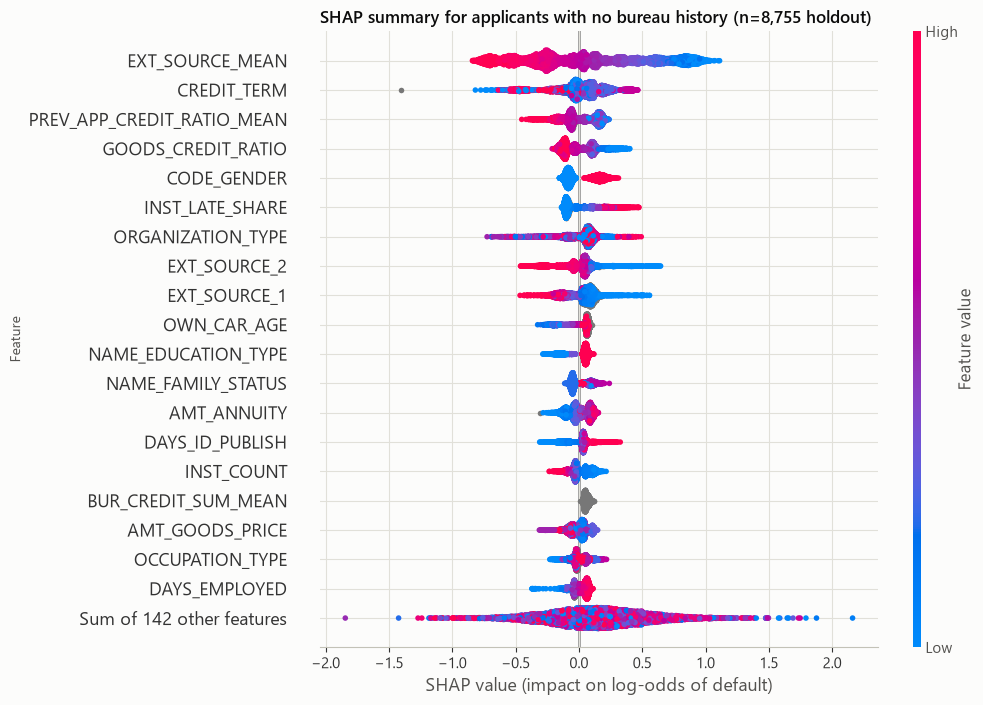

,"full model, no-bureau group",mean |SHAP| (a),"full model, with-bureau group",mean |SHAP| (b),"alt-data-only model, no-bureau group",mean |SHAP| (c)
1,EXT_SOURCE_MEAN,0.4106,EXT_SOURCE_MEAN,0.3538,CREDIT_TERM,0.1549
2,CREDIT_TERM,0.1350,CREDIT_TERM,0.1242,CODE_GENDER,0.1418
3,PREV_APP_CREDIT_RATIO_MEAN,0.1172,PREV_APP_CREDIT_RATIO_MEAN,0.1217,PREV_APP_CREDIT_RATIO_MEAN,0.1388
4,GOODS_CREDIT_RATIO,0.1139,GOODS_CREDIT_RATIO,0.1160,GOODS_CREDIT_RATIO,0.1331
5,CODE_GENDER,0.1132,EXT_SOURCE_3,0.1159,INST_LATE_SHARE,0.1222
6,INST_LATE_SHARE,0.1118,ORGANIZATION_TYPE,0.1135,DAYS_LAST_PHONE_CHANGE,0.1094
7,ORGANIZATION_TYPE,0.1049,CODE_GENDER,0.1090,ORGANIZATION_TYPE,0.1003
8,EXT_SOURCE_2,0.1019,INST_LATE_SHARE,0.0983,NAME_EDUCATION_TYPE,0.0946
9,EXT_SOURCE_1,0.0974,EXT_SOURCE_2,0.0938,DAYS_ID_PUBLISH,0.0856
10,OWN_CAR_AGE,0.0826,EXT_SOURCE_1,0.0891,OWN_CAR_AGE,0.0824


In [17]:
nb_rows = holdout[no_bureau]
ex_nb = shap_explanation(lgbm, nb_rows[FEATURES])
ex_nb_plot = shap.Explanation(values=ex_nb.values, base_values=ex_nb.base_values,
                              data=numeric_view(nb_rows[FEATURES]).to_numpy(), feature_names=FEATURES)
shap.plots.beeswarm(ex_nb_plot, max_display=20, show=False, plot_size=(9, 8))
fig = plt.gcf()
plt.title(f"SHAP summary for applicants with no bureau history (n={len(nb_rows):,} holdout)", loc="left",
          fontsize=12, fontweight="semibold")
plt.xlabel("SHAP value (impact on log-odds of default)")
plt.ylabel("Feature")
savefig(fig, "31_shap_beeswarm_no_bureau.png")
plt.show()

alt_model, alt_feats = ablation_models["Alternative data only"]
ex_alt_nb = shap_explanation(alt_model, nb_rows[alt_feats])
with_bureau_in_sample = shap_rows["HAS_BUREAU_HISTORY"].to_numpy() == 1
top_compare = pd.DataFrame({
    "full model, no-bureau group": mean_abs_shap(ex_nb).head(15).index,
    "mean |SHAP| (a)": mean_abs_shap(ex_nb).head(15).to_numpy(),
    "full model, with-bureau group": mean_abs_shap(ex[with_bureau_in_sample], FEATURES).head(15).index,
    "mean |SHAP| (b)": mean_abs_shap(ex[with_bureau_in_sample], FEATURES).head(15).to_numpy(),
    "alt-data-only model, no-bureau group": mean_abs_shap(ex_alt_nb).head(15).index,
    "mean |SHAP| (c)": mean_abs_shap(ex_alt_nb).head(15).to_numpy(),
}, index=range(1, 16))
display(top_compare.round(4))

**Insight:** For applicants without bureau history, the full model relies even more on the external scores
(`EXT_SOURCE_MEAN` mean |SHAP| 0.4106 vs 0.3538 for applicants with bureau history). After that come loan structure
(`CREDIT_TERM`, `PREV_APP_CREDIT_RATIO_MEAN`, `GOODS_CREDIT_RATIO`), `CODE_GENDER` and `INST_LATE_SHARE` (6th here,
8th for applicants with bureau history). Without external scores and bureau data, the alternative-data-only model
ranks for this group: `CREDIT_TERM` (0.1549), `CODE_GENDER` (0.1418), `PREV_APP_CREDIT_RATIO_MEAN` (0.1388),
`GOODS_CREDIT_RATIO` (0.1331) and `INST_LATE_SHARE` (0.1222), then `DAYS_LAST_PHONE_CHANGE`, `ORGANIZATION_TYPE` and
`NAME_EDUCATION_TYPE`. For thin-file applicants the signal therefore comes from how the loan is structured, past
behaviour with the lender and stability indicators, and, worryingly, also from gender.

## D. Fairness check at the chosen threshold
Approval rate, actual default rate and the share of good applicants (TARGET = 0) who are rejected, by
`CODE_GENDER` and by age group, on the holdout at the cost-optimal threshold.

In [18]:
AGE_BINS, AGE_LABELS = [20, 30, 40, 50, 60, 70], ["20-29", "30-39", "40-49", "50-59", "60-69"]


def fairness_table(df, col, prob, threshold):
    d = pd.DataFrame({"group": df[col].to_numpy(), "y": df[TARGET].to_numpy(), "approve": prob < threshold})
    g = d.groupby("group", observed=True)
    out = pd.DataFrame({
        "applicants": g.size(),
        "actual_default_rate": g["y"].mean(),
        "approval_rate": g["approve"].mean(),
        "default_rate_approved": d[d["approve"]].groupby("group", observed=True)["y"].mean(),
        "good_applicants_rejected": d[d["y"] == 0].groupby("group", observed=True)["approve"].apply(lambda a: 1 - a.mean()),
    })
    return out


holdout_f = holdout.assign(AGE_GROUP=pd.cut(holdout["AGE_YEARS"], AGE_BINS, right=False, labels=AGE_LABELS))
FMT = {"applicants": "{:,}", "actual_default_rate": "{:.2%}", "approval_rate": "{:.2%}",
       "default_rate_approved": "{:.2%}", "good_applicants_rejected": "{:.2%}"}
gender_fair = fairness_table(holdout_f, "CODE_GENDER", p_ho, T_STAR)
age_fair = fairness_table(holdout_f, "AGE_GROUP", p_ho, T_STAR)
print(f"threshold {T_STAR:.2f} — by CODE_GENDER")
display(gender_fair.style.format(FMT))
print("by age group")
display(age_fair.style.format(FMT))
gap_full = gender_fair.loc["F", "approval_rate"] - gender_fair.loc["M", "approval_rate"]
print(f"approval-rate gap (F − M): {gap_full:+.2%} | approval-rate ratio M/F: "
      f"{gender_fair.loc['M', 'approval_rate'] / gender_fair.loc['F', 'approval_rate']:.4f}")

threshold 0.70 — by CODE_GENDER


,applicants,actual_default_rate,approval_rate,default_rate_approved,good_applicants_rejected
group,,,,,
F,"40,544",6.99%,91.95%,5.17%,6.25%
M,"20,958",10.16%,84.60%,6.51%,11.97%


by age group


,applicants,actual_default_rate,approval_rate,default_rate_approved,good_applicants_rejected
group,,,,,
20-29,"8,917",11.24%,79.30%,7.16%,17.06%
30-39,"16,468",9.59%,85.88%,6.23%,10.93%
40-49,"15,363",7.53%,90.87%,5.27%,6.91%
50-59,"13,539",6.40%,94.69%,5.07%,3.96%
60-69,"7,215",4.99%,97.23%,4.38%,2.14%


approval-rate gap (F − M): +7.35% | approval-rate ratio M/F: 0.9201


saved reports/figures/32_fairness_gender_age.png


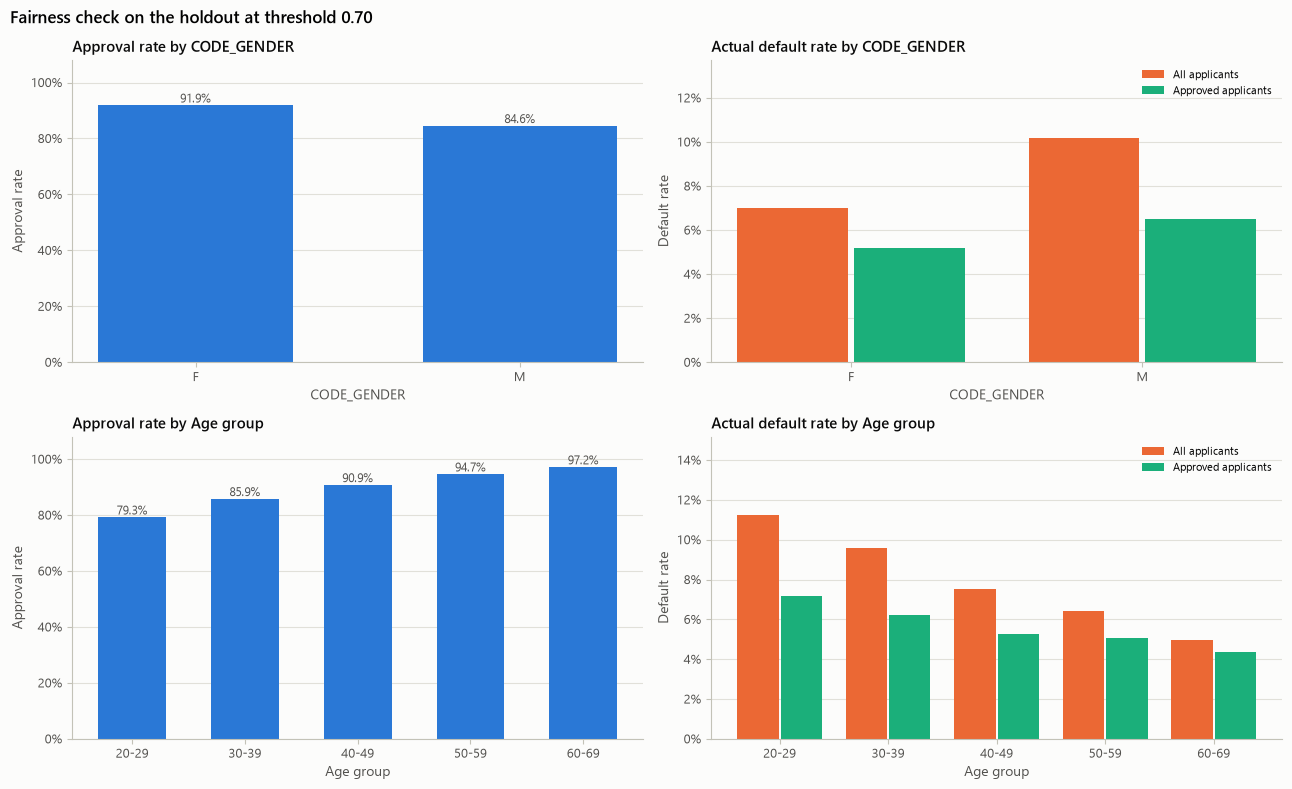

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (table, label) in enumerate([(gender_fair, "CODE_GENDER"), (age_fair, "Age group")]):
    ax_a, ax_d = axes[row, 0], axes[row, 1]
    idx = [str(i) for i in table.index]
    ax_a.bar(idx, table["approval_rate"], color=SERIES[0], width=0.6)
    for xi, v in enumerate(table["approval_rate"]):
        ax_a.text(xi, v, f"{v:.1%}", ha="center", va="bottom", fontsize=8.5, color=INK_2)
    ax_a.set_ylim(0, 1.08)
    ax_a.set_title(f"Approval rate by {label}", loc="left", fontsize=11)
    ax_a.set_ylabel("Approval rate")
    ax_d.bar(np.arange(len(idx)) - 0.2, table["actual_default_rate"], width=0.38, color=SERIES[1],
             label="All applicants")
    ax_d.bar(np.arange(len(idx)) + 0.2, table["default_rate_approved"], width=0.38, color=SERIES[2],
             label="Approved applicants")
    ax_d.set_xticks(np.arange(len(idx)), idx)
    ax_d.set_title(f"Actual default rate by {label}", loc="left", fontsize=11)
    ax_d.set_ylabel("Default rate")
    ax_d.set_ylim(0, table[["actual_default_rate", "default_rate_approved"]].to_numpy().max() * 1.35)
    ax_d.legend(loc="upper right", fontsize=8)
    for ax in (ax_a, ax_d):
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
        ax.set_xlabel(label)
        ax.grid(axis="x", visible=False)
fig.suptitle(f"Fairness check on the holdout at threshold {T_STAR:.2f}", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
savefig(fig, "32_fairness_gender_age.png")
plt.show()

**Insight:** At threshold 0.70 women are approved more often than men (91.95% vs 84.60%, a gap of 7.35 percentage
points), and men's actual default rate is also higher (10.16% vs 6.99%). Good applicants are rejected 1.92 times as
often among men (11.97% vs 6.25%). By age, approval rises from 79.30% (20–29) to 97.23% (60–69), in line with actual
default rates (11.24% down to 4.99%), and 17.06% of good applicants aged 20–29 are rejected vs 2.14% at 60–69. The
approval gaps largely follow real differences in default rates, but the unequal false-rejection rates mean young
and male applicants bear more of the cost of the model's mistakes.

### D2. Retraining without `CODE_GENDER`
Same hyperparameters and procedure: 5-fold CV on train gives OOF predictions, from which the model's own
cost-optimal threshold is chosen; the model refitted on train is then evaluated once on the holdout.

In [20]:
feats_ng = [f for f in FEATURES if f != "CODE_GENDER"]
cv_ng = cross_validate_gbm(fit_lgbm, BEST_PARAMS, train[feats_ng], train[TARGET])
t_ng = optimal_threshold(threshold_sweep(y_oof, cv_ng["oof"], credit_oof))
lgbm_ng = fit_lgbm(BEST_PARAMS, train[feats_ng], train[TARGET])
p_ng = lgbm_ng.predict_proba(holdout[feats_ng])[:, 1]
gender_fair_ng = fairness_table(holdout_f, "CODE_GENDER", p_ng, t_ng)
gap_ng = gender_fair_ng.loc["F", "approval_rate"] - gender_fair_ng.loc["M", "approval_rate"]

compare_ng = pd.DataFrame({
    "with CODE_GENDER": {"CV AUC (train)": cfg["cv_auc_mean"], "holdout AUC": roc_auc_score(y_ho, p_ho),
                         "threshold (chosen on OOF)": T_STAR,
                         "approval rate F": gender_fair.loc["F", "approval_rate"],
                         "approval rate M": gender_fair.loc["M", "approval_rate"], "approval gap F−M": gap_full,
                         "holdout total cost": decision_summary(y_ho, p_ho, credit_ho, T_STAR)["total_cost"]},
    "without CODE_GENDER": {"CV AUC (train)": cv_ng["auc_mean"], "holdout AUC": roc_auc_score(y_ho, p_ng),
                            "threshold (chosen on OOF)": t_ng,
                            "approval rate F": gender_fair_ng.loc["F", "approval_rate"],
                            "approval rate M": gender_fair_ng.loc["M", "approval_rate"], "approval gap F−M": gap_ng,
                            "holdout total cost": decision_summary(y_ho, p_ng, credit_ho, t_ng)["total_cost"]},
})
compare_ng["difference"] = compare_ng["without CODE_GENDER"] - compare_ng["with CODE_GENDER"]
display(compare_ng.style.format("{:.4f}").format("{:,.0f}", subset=pd.IndexSlice[["holdout total cost"], :]))
display(gender_fair_ng.style.format(FMT))

,with CODE_GENDER,without CODE_GENDER,difference
CV AUC (train),0.7758,0.7743,-0.0015
holdout AUC,0.7819,0.7803,-0.0016
threshold (chosen on OOF),0.7000,0.7200,0.0200
approval rate F,0.9195,0.9280,0.0085
approval rate M,0.8460,0.8769,0.0310
approval gap F−M,0.0735,0.0510,-0.0225
holdout total cost,"1,431,358,554","1,444,856,943","13,498,389"


,applicants,actual_default_rate,approval_rate,default_rate_approved,good_applicants_rejected
group,,,,,
F,"40,544",6.99%,92.80%,5.35%,5.56%
M,"20,958",10.16%,87.69%,7.02%,9.25%


**Proxy check:** can gender be recovered from the remaining features? A LightGBM is trained on the training set
to predict `CODE_GENDER` from the features without `CODE_GENDER`, and scored on the holdout.

In [21]:
y_gender_tr = (train["CODE_GENDER"] == "M").astype(int)
y_gender_ho = (holdout["CODE_GENDER"] == "M").astype(int)
proxy = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1)
proxy.fit(train[feats_ng], y_gender_tr)
proxy_auc = roc_auc_score(y_gender_ho, proxy.predict_proba(holdout[feats_ng])[:, 1])
proxy_gain = pd.Series(proxy.booster_.feature_importance("gain"), index=feats_ng)
print(f"AUC for predicting gender from the other features: {proxy_auc:.4f}")
print("top 5 proxy features by gain share:")
print((proxy_gain / proxy_gain.sum()).sort_values(ascending=False).head(5).round(4).to_string())

AUC for predicting gender from the other features: 0.9094
top 5 proxy features by gain share:
OCCUPATION_TYPE      0.4523
OWN_CAR_AGE          0.0955
ORGANIZATION_TYPE    0.0918
EXT_SOURCE_1         0.0633
FLAG_OWN_CAR         0.0339


**Insight (trade-off):** Dropping `CODE_GENDER` costs very little accuracy (holdout AUC 0.7819 → 0.7803, −0.0016; CV
AUC −0.0015) and raises total holdout cost by 13,498,389 (0.94%), while narrowing the approval gap from 7.35 to 5.10
percentage points (with its own OOF-chosen threshold of 0.72). The gap does not disappear because (a) men's actual
default rate is higher (10.16% vs 6.99%), and (b) gender can be reconstructed from the other features: a model
predicting gender from them reaches AUC 0.9094, mostly through `OCCUPATION_TYPE` (45.23% of its gain), `OWN_CAR_AGE`
and `ORGANIZATION_TYPE`. Removing the attribute ("fairness through unawareness") is therefore only a partial remedy.
A lender would also need outcome-based monitoring (e.g. comparing false-rejection rates across groups) and a legal
review of which attributes may be used.

### Supporting analysis: applicants with neither bureau nor previous-application data

The truly new-to-credit group (no Credit Bureau record *and* no previous Home Credit application) is too small for
its own section in B1. Reported here for report section 10, with a fresh random generator so the intervals above
are unchanged.

In [22]:
neither = (holdout["HAS_BUREAU_HISTORY"].to_numpy() == 0) & (holdout["HAS_PREV_APPLICATION"].to_numpy() == 0)
rng = np.random.default_rng(RANDOM_STATE)  # fresh generator: auc_with_ci reads the global rng
auc_n, lo_n, hi_n = auc_with_ci(y_ho[neither], p_ho[neither])
print(f"holdout applicants with neither history: {int(neither.sum()):,} ({int(y_ho[neither].sum())} defaults, "
      f"default rate {y_ho[neither].mean():.2%})")
print(f"LightGBM AUC {auc_n:.4f} (95% bootstrap interval {lo_n:.4f}-{hi_n:.4f})")

holdout applicants with neither history: 480 (35 defaults, default rate 7.29%)
LightGBM AUC 0.7893 (95% bootstrap interval 0.7295-0.8564)


**Insight:** Only 480 holdout applicants (35 defaults) have neither kind of history. LightGBM's AUC for them is
0.7893, but the 95% interval (0.7295–0.8564) is too wide to support any conclusion: the data cannot tell us how well
the model works for genuinely new-to-credit customers.